In [2]:

!pip install pandas numpy matplotlib seaborn

In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
transactions = pd.read_csv("/content/transactions.csv")
customers = pd.read_csv("/content/customers.csv")
devices = pd.read_csv("/content/devices.csv")
merchants = pd.read_csv("/content/merchants.csv")
alerts = pd.read_csv("/content/alerts.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
datasets = {
    "Transactions": transactions,
    "Customers": customers,
    "Devices": devices,
    "Merchants": merchants,
    "Alerts": alerts
}

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    display(df.head())


Dataset: Transactions
Rows and columns: (5000, 7)
Column names: ['transaction_id', 'customer_id', 'merchant_id', 'time', 'amount', 'merchant_category', 'channel']


,transaction_id,customer_id,merchant_id,time,amount,merchant_category,channel
0,TXN000001,1538,219,2026-02-07 15:39:30,32.89,healthcare,UPI
1,TXN000002,1519,222,2026-02-02 02:14:13,54.77,food_delivery,UPI
2,TXN000003,1492,222,2026-03-16 08:58:36,201.85,fashion,UPI
3,TXN000004,1514,256,2026-01-14 13:34:21,180.03,electronics,UPI
4,TXN000005,1042,276,2026-02-18 03:59:53,57.67,food_delivery,UPI



Dataset: Customers
Rows and columns: (600, 4)
Column names: ['customer_id', 'customer_segment', 'region', 'tenure_months']


,customer_id,customer_segment,region,tenure_months
0,1001,Small Business,East,34.0
1,1002,Student,North,60.0
2,1003,Professional,West,34.0
3,1004,Small Business,Central,7.0
4,1005,Professional,South,115.0



Dataset: Devices
Rows and columns: (5000, 4)
Column names: ['transaction_id', 'customer_id', 'device_type', 'new_device_flag']


,transaction_id,customer_id,device_type,new_device_flag
0,TXN000001,1538,Windows PC,Yes
1,TXN000002,1519,Windows PC,No
2,TXN000003,1492,Android Phone,No
3,TXN000004,1514,Android Phone,No
4,TXN000005,1042,iPhone,Yes



Dataset: Merchants
Rows and columns: (80, 3)
Column names: ['merchant_id', 'merchant_category', 'region']


,merchant_id,merchant_category,region
0,201,healthcare,East
1,202,food_delivery,East
2,203,fashion,Central
3,204,electronics,East
4,205,grocery,West



Dataset: Alerts
Rows and columns: (600, 4)
Column names: ['alert_id', 'transaction_id', 'review_status', 'reason_category']


,alert_id,transaction_id,review_status,reason_category
0,ALT00001,TXN001748,Closed,New Device
1,ALT00002,TXN004500,Reviewed,Unusual Time
2,ALT00003,TXN002673,Escalated,Unusual Time
3,ALT00004,TXN002537,Escalated,New Device
4,ALT00005,TXN004713,Reviewed,Unusual Amount


In [6]:
for name, df in datasets.items():
    print("\n==========", name, "==========")

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())


========== Transactions ==========

Data types:
transaction_id        object
customer_id            int64
merchant_id            int64
time                  object
amount               float64
merchant_category     object
channel               object
dtype: object

Missing values:
transaction_id        0
customer_id           0
merchant_id           0
time                  0
amount                0
merchant_category    45
channel               0
dtype: int64

Duplicate rows: 0

========== Customers ==========

Data types:
customer_id           int64
customer_segment     object
region               object
tenure_months       float64
dtype: object

Missing values:
customer_id         0
customer_segment    0
region              0
tenure_months       9
dtype: int64

Duplicate rows: 0

========== Devices ==========

Data types:
transaction_id     object
customer_id         int64
device_type        object
new_device_flag    object
dtype: object

Missing values:
transaction_id      0
custome

In [7]:
print("Transaction amount statistics:")
display(transactions["amount"].describe())

print("\nChannel labels:")
print(transactions["channel"].value_counts(dropna=False))

print("\nDuplicate transaction IDs:")
print(
    transactions[
        transactions.duplicated(
            subset=["transaction_id"],
            keep=False
        )
    ]
)

Transaction amount statistics:


,amount
count,5000.000000
mean,272.255493
std,663.742788
min,4.910000
25%,73.620000
50%,150.230000
75%,295.492500
max,24728.935432



Channel labels:
channel
UPI            2596
Card           1227
Net Banking     661
Wallet          476
upi              15
CARD             11
wallet            8
net banking       6
Name: count, dtype: int64

Duplicate transaction IDs:
     transaction_id  customer_id  merchant_id                 time   amount  \
177       TXN000178         1226          245  2026-01-27 16:44:38    59.22   
178       TXN000178         1521          252  2026-03-26 07:11:58    99.72   
908       TXN000909         1076          243  2026-03-05 18:04:38   295.89   
909       TXN000909         1367          262  2026-02-18 00:55:48   155.13   
1045      TXN001046         1166          226  2026-02-08 06:39:47    55.47   
1046      TXN001046         1295          234  2026-01-25 18:57:51   101.36   
1382      TXN001383         1535          275  2026-03-18 14:26:43    21.00   
1383      TXN001383         1098          208  2026-02-15 14:56:00   858.05   
1672      TXN001673         1273          264  202

In [8]:
# Keep original datasets unchanged
cleaned_transactions = transactions.copy()
cleaned_customers = customers.copy()
cleaned_devices = devices.copy()
cleaned_merchants = merchants.copy()
cleaned_alerts = alerts.copy()

# Standardize text labels
for df in [
    cleaned_transactions,
    cleaned_customers,
    cleaned_devices,
    cleaned_merchants,
    cleaned_alerts
]:
    for col in df.select_dtypes(
        include=["object", "string"]
    ).columns:
        df[col] = df[col].str.strip()

# Standardize transaction channel labels
cleaned_transactions["channel"] = (
    cleaned_transactions["channel"].str.lower()
)

# Handle missing merchant categories
cleaned_transactions["merchant_category"] = (
    cleaned_transactions["merchant_category"]
    .fillna("Unknown")
)

print("Initial cleaning completed!")

Initial cleaning completed!


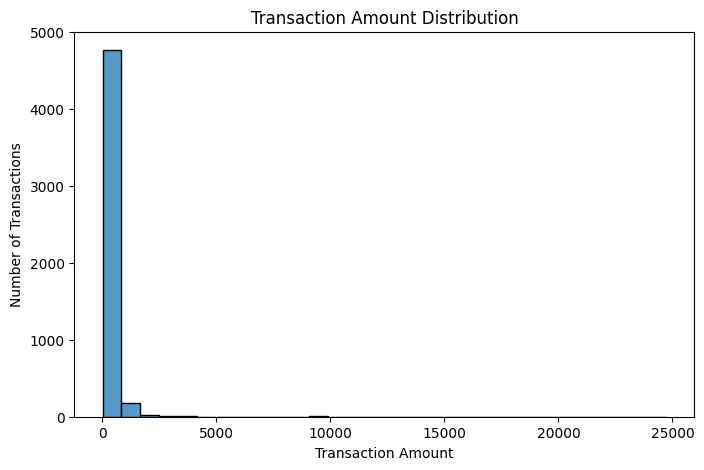

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=cleaned_transactions,
    x="amount",
    bins=30
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

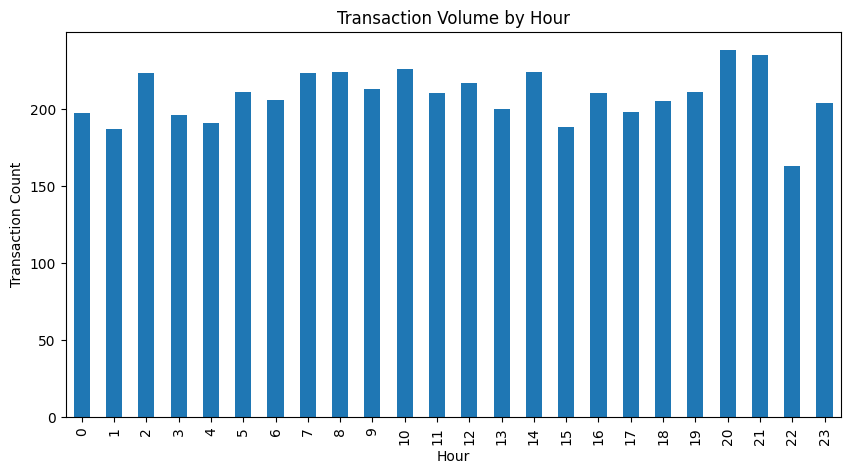

In [10]:
cleaned_transactions["time"] = pd.to_datetime(
    cleaned_transactions["time"],
    errors="coerce"
)

cleaned_transactions["hour"] = (
    cleaned_transactions["time"].dt.hour
)

hourly_volume = (
    cleaned_transactions.groupby("hour").size()
)

hourly_volume.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Transaction Volume by Hour")
plt.xlabel("Hour")
plt.ylabel("Transaction Count")
plt.show()

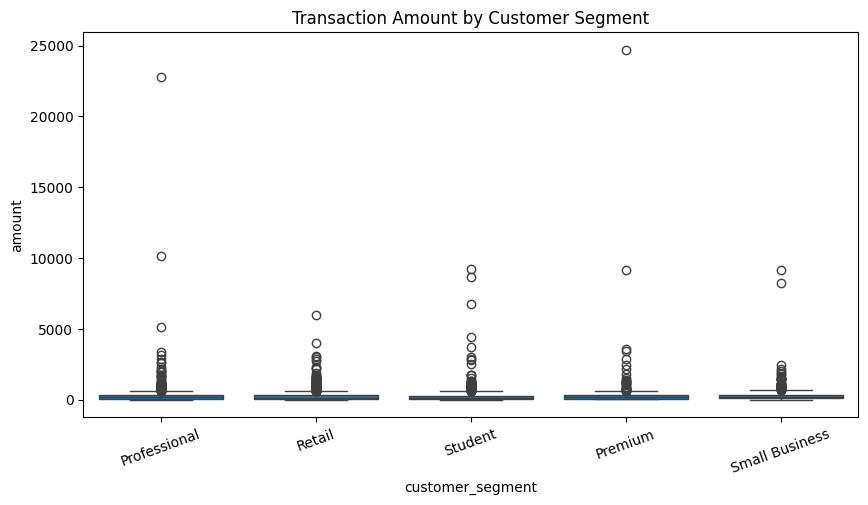

In [11]:
analysis_df = cleaned_transactions.merge(
    cleaned_customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=analysis_df,
    x="customer_segment",
    y="amount"
)

plt.title("Transaction Amount by Customer Segment")
plt.xticks(rotation=20)
plt.show()

In [12]:
device_analysis = cleaned_transactions[
    ["transaction_id", "amount"]
].merge(
    cleaned_devices[
        ["transaction_id", "new_device_flag"]
    ],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

display(
    device_analysis.groupby("new_device_flag")["amount"]
    .agg(["count", "mean", "median"])
)

MergeError: Merge keys are not unique in either left or right dataset; not a one-to-one merge

In [13]:
print("Duplicate IDs in transactions:",
      cleaned_transactions["transaction_id"].duplicated().sum())

print("Duplicate IDs in devices:",
      cleaned_devices["transaction_id"].duplicated().sum())


Duplicate IDs in transactions: 20
Duplicate IDs in devices: 20


,count,mean,median
new_device_flag,,,
No,4221,272.225923,150.230
Yes,704,271.999124,150.025


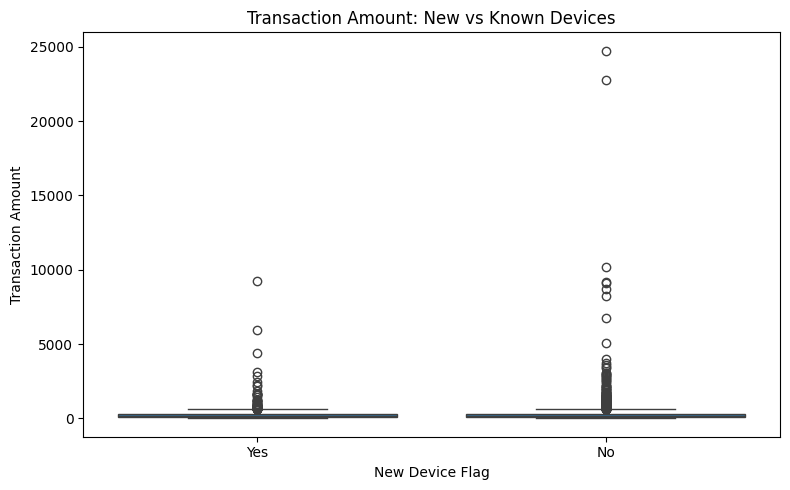

In [14]:
# Keep only the device columns needed for this analysis
device_data = cleaned_devices[
    ["transaction_id", "new_device_flag"]
].copy()

# Remove duplicate device records for this comparison
device_data = device_data.drop_duplicates(
    subset=["transaction_id"],
    keep="first"
)

# Merge without requiring unique transaction IDs on the left
device_analysis = cleaned_transactions[
    ["transaction_id", "amount"]
].merge(
    device_data,
    on="transaction_id",
    how="left",
    validate="many_to_one"
)

# Compare transaction amounts by device status
display(
    device_analysis.groupby("new_device_flag")["amount"]
    .agg(["count", "mean", "median"])
)

# Visualize the comparison
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=device_analysis,
    x="new_device_flag",
    y="amount"
)

plt.title("Transaction Amount: New vs Known Devices")
plt.xlabel("New Device Flag")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()


,alert_id
merchant_category,
fashion,95
travel,93
utilities,91
healthcare,89
food_delivery,84
electronics,81
grocery,72


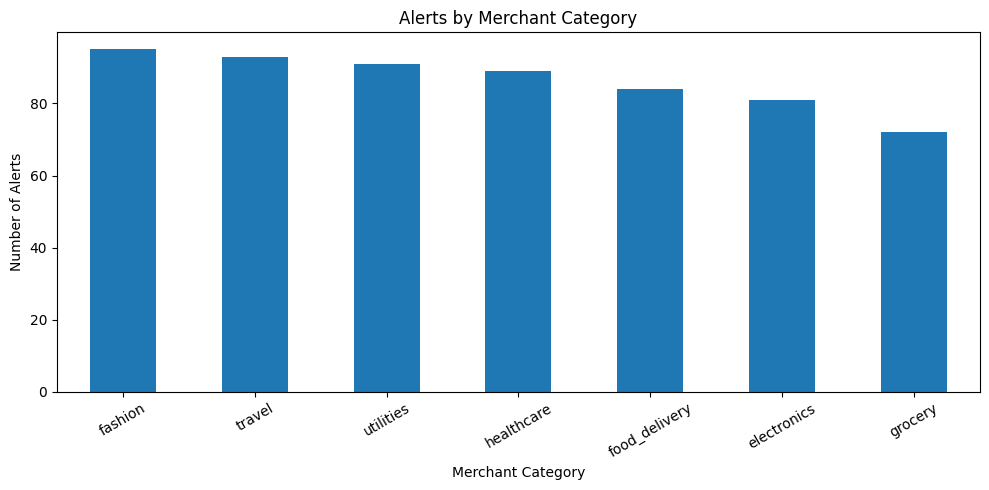

In [15]:
# Prepare transaction and merchant information
merchant_analysis = cleaned_transactions[
    ["transaction_id", "merchant_id", "amount"]
].merge(
    cleaned_merchants[
        ["merchant_id", "merchant_category", "region"]
    ],
    on="merchant_id",
    how="left",
    validate="many_to_one"
)

# Attach alert information
alert_data = cleaned_alerts[
    ["transaction_id", "alert_id", "review_status", "reason_category"]
].drop_duplicates(subset=["alert_id"])

merchant_alert_analysis = merchant_analysis.merge(
    alert_data,
    on="transaction_id",
    how="left"
)

# Count alerts by merchant category
alert_counts = (
    merchant_alert_analysis.dropna(subset=["alert_id"])
    .groupby("merchant_category")["alert_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(alert_counts)

# Plot the results
alert_counts.plot(kind="bar", figsize=(10, 5))
plt.title("Alerts by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Number of Alerts")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,transaction_count,total_amount,average_amount
region,,,
South,1389,400679.797852,288.466377
West,1085,291950.226397,269.078550
Central,1005,256774.490631,255.497006
North,919,235682.934049,256.455859
East,602,176190.015837,292.674445


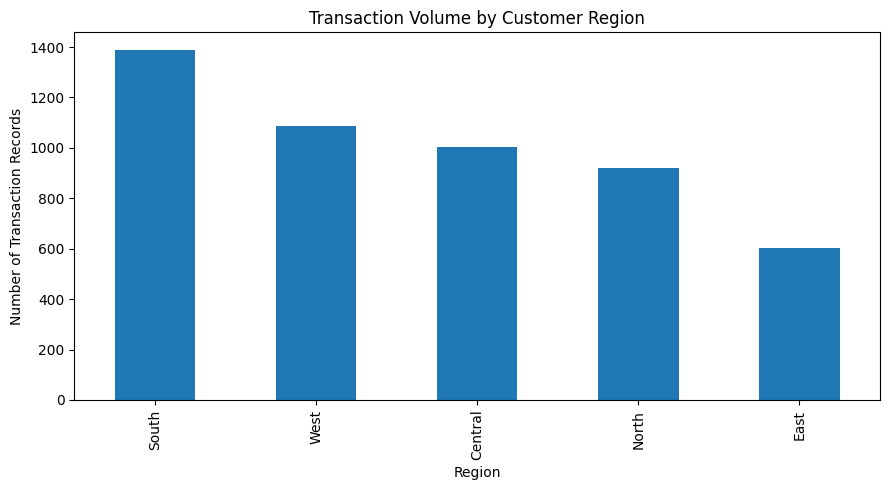

In [16]:
# Use customer region for regional analysis
regional_analysis = cleaned_transactions[
    ["transaction_id", "customer_id", "amount"]
].merge(
    cleaned_customers[
        ["customer_id", "region"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculate regional transaction statistics
regional_summary = (
    regional_analysis.groupby("region")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("transaction_count", ascending=False)
)

display(regional_summary)

# Plot regional volume
regional_summary["transaction_count"].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Transaction Volume by Customer Region")
plt.xlabel("Region")
plt.ylabel("Number of Transaction Records")
plt.tight_layout()
plt.show()

In [17]:
# Convert time to datetime
cleaned_transactions["time"] = pd.to_datetime(
    cleaned_transactions["time"],
    errors="coerce"
)

# Extract hour
cleaned_transactions["hour"] = (
    cleaned_transactions["time"].dt.hour
)

# Extract day of week
cleaned_transactions["day_of_week"] = (
    cleaned_transactions["time"].dt.day_name()
)

# Flag high transaction amounts
threshold = cleaned_transactions["amount"].quantile(0.95)

cleaned_transactions["high_amount_flag"] = (
    cleaned_transactions["amount"] > threshold
).astype(int)

display(cleaned_transactions.head())

,transaction_id,customer_id,merchant_id,time,amount,merchant_category,channel,hour,day_of_week,high_amount_flag
0,TXN000001,1538,219,2026-02-07 15:39:30,32.89,healthcare,upi,15,Saturday,0
1,TXN000002,1519,222,2026-02-02 02:14:13,54.77,food_delivery,upi,2,Monday,0
2,TXN000003,1492,222,2026-03-16 08:58:36,201.85,fashion,upi,8,Monday,0
3,TXN000004,1514,256,2026-01-14 13:34:21,180.03,electronics,upi,13,Wednesday,0
4,TXN000005,1042,276,2026-02-18 03:59:53,57.67,food_delivery,upi,3,Wednesday,0


In [18]:
cleaned_transactions.to_csv(
    "cleaned_transactions.csv",
    index=False
)

from google.colab import files
files.download("cleaned_transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# Convert channel categories into numerical columns
encoded_channels = pd.get_dummies(
    cleaned_transactions["channel"],
    prefix="channel",
    dtype=int
)

display(encoded_channels.head())

,channel_card,channel_net banking,channel_upi,channel_wallet
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0


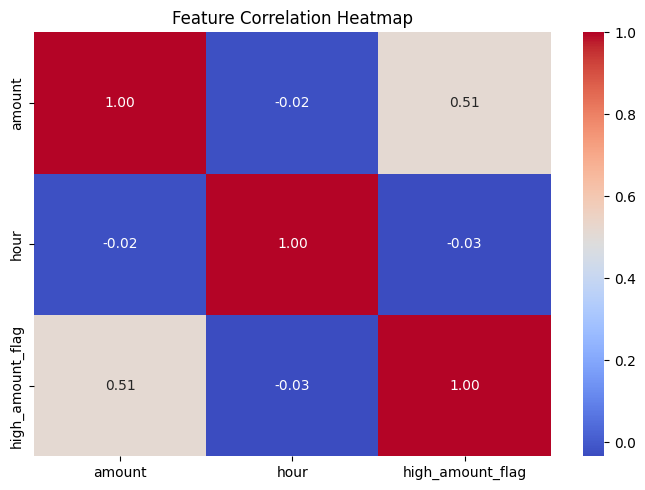

In [20]:
# Select useful numerical features
selected_features = cleaned_transactions[
    ["amount", "hour", "high_amount_flag"]
].copy()

# Check correlations
plt.figure(figsize=(7, 5))

sns.heatmap(
    selected_features.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [21]:
print("Dataset shape:", cleaned_transactions.shape)
print("Missing values:")
print(cleaned_transactions.isnull().sum())

display(cleaned_transactions.head())

Dataset shape: (5000, 10)
Missing values:
transaction_id       0
customer_id          0
merchant_id          0
time                 0
amount               0
merchant_category    0
channel              0
hour                 0
day_of_week          0
high_amount_flag     0
dtype: int64


,transaction_id,customer_id,merchant_id,time,amount,merchant_category,channel,hour,day_of_week,high_amount_flag
0,TXN000001,1538,219,2026-02-07 15:39:30,32.89,healthcare,upi,15,Saturday,0
1,TXN000002,1519,222,2026-02-02 02:14:13,54.77,food_delivery,upi,2,Monday,0
2,TXN000003,1492,222,2026-03-16 08:58:36,201.85,fashion,upi,8,Monday,0
3,TXN000004,1514,256,2026-01-14 13:34:21,180.03,electronics,upi,13,Wednesday,0
4,TXN000005,1042,276,2026-02-18 03:59:53,57.67,food_delivery,upi,3,Wednesday,0


In [22]:
cleaned_transactions.to_csv(
    "cleaned_transactions.csv",
    index=False
)

from google.colab import files
files.download("cleaned_transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>